<a href="https://colab.research.google.com/github/o660s/Visual_Code_Flow_Tracker/blob/main/Visual_Code_Flow_Tracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!apt-get -qq install graphviz
!pip install -q graphviz streamlit


In [2]:

import ast
import graphviz
import streamlit

print("Visual Code Flow Tracker")
print("All libraries installed successfully!")


Visual Code Flow Tracker
All libraries installed successfully!


In [3]:

import ast

class CodeAnalyzer(ast.NodeVisitor):

    def __init__(self, source_code):
        self.source_code = source_code
        self.results = []

    def add_result(self, node, category, details):
        self.results.append({
            "line": node.lineno,
            "type": category,
            "code": ast.get_source_segment(
                self.source_code, node
            ),
            "details": details
        })

    # Detect variable assignments
    def visit_Assign(self, node):
        variables = [
            ast.unparse(target)
            for target in node.targets
        ]

        self.add_result(
            node, "Variable Assignment",
            f"Variables: {', '.join(variables)}"
        )

        self.generic_visit(node)

    # Detect print statements
    def visit_Expr(self, node):
        if isinstance(node.value, ast.Call):
            if isinstance(node.value.func, ast.Name):
                if node.value.func.id == "print":
                    self.add_result(
                        node, "Print Statement",
                        "Displays output"
                    )

        self.generic_visit(node)

    # Detect if conditions
    def visit_If(self, node):
        condition = ast.unparse(node.test)

        self.add_result(
            node, "If Condition",
            f"Condition: {condition}"
        )

        if node.orelse:
            self.results.append({
                "line": node.lineno,
                "type": "Else Branch",
                "code": "else",
                "details": "Alternative execution path"
            })

        self.generic_visit(node)

    # Detect for loops
    def visit_For(self, node):
        self.add_result(
            node, "For Loop",
            f"Loop target: {ast.unparse(node.target)}"
        )

        self.generic_visit(node)

    # Detect while loops
    def visit_While(self, node):
        self.add_result(
            node, "While Loop",
            f"Condition: {ast.unparse(node.test)}"
        )

        self.generic_visit(node)

    # Detect functions
    def visit_FunctionDef(self, node):
        self.add_result(
            node, "Function Definition",
            f"Function: {node.name}"
        )

        self.generic_visit(node)

    # Detect return statements
    def visit_Return(self, node):
        value = (
            ast.unparse(node.value)
            if node.value else "None"
        )

        self.add_result(
            node, "Return Statement",
            f"Returns: {value}"
        )

    # Main analysis function
    def analyze(self):
        try:
            tree = ast.parse(self.source_code)
            self.visit(tree)
            return self.results

        except SyntaxError as error:
            return {
                "error": f"Syntax Error: {error}"
            }

def analyze_code(source_code):
    analyzer = CodeAnalyzer(source_code)
    return analyzer.analyze()

In [4]:

sample_code = """
x = 10
y = 20

if x < y:
    print("X is smaller")
else:
    print("Y is smaller")

for i in range(5):
    print(i)

def greet():
    return "Hello"
"""

results = analyze_code(sample_code)

for item in results:
    print("-------------------------")
    print("Line:", item["line"])
    print("Type:", item["type"])
    print("Code:", item["code"])
    print("Details:", item["details"])


-------------------------
Line: 2
Type: Variable Assignment
Code: x = 10
Details: Variables: x
-------------------------
Line: 3
Type: Variable Assignment
Code: y = 20
Details: Variables: y
-------------------------
Line: 5
Type: If Condition
Code: if x < y:
    print("X is smaller")
else:
    print("Y is smaller")
Details: Condition: x < y
-------------------------
Line: 5
Type: Else Branch
Code: else
Details: Alternative execution path
-------------------------
Line: 6
Type: Print Statement
Code: print("X is smaller")
Details: Displays output
-------------------------
Line: 8
Type: Print Statement
Code: print("Y is smaller")
Details: Displays output
-------------------------
Line: 10
Type: For Loop
Code: for i in range(5):
    print(i)
Details: Loop target: i
-------------------------
Line: 11
Type: Print Statement
Code: print(i)
Details: Displays output
-------------------------
Line: 13
Type: Function Definition
Code: def greet():
    return "Hello"
Details: Function: greet
-------

In [5]:

import ast
from graphviz import Digraph
from IPython.display import display, Image

class FlowchartGenerator:

    def __init__(self, source_code):
        self.source_code = source_code
        self.graph = Digraph("Code_Flow")
        self.graph.attr(rankdir="TB")
        self.graph.attr("node", fontname="Arial")
        self.counter = 0

    # Generate unique node IDs
    def new_id(self):
        self.counter += 1
        return f"node{self.counter}"

    # Create a flowchart node
    def add_node(self, label, shape="box"):
        node_id = self.new_id()
        self.graph.node(
            node_id,
            label=label,
            shape=shape
        )
        return node_id

    # Connect two nodes
    def connect(self, source, target, label=""):
        self.graph.edge(
            source, target, label=label
        )

    # Process a block of statements
    def build_block(self, statements, incoming):

        for stmt in statements:

            # IF / ELSE CONDITION
            if isinstance(stmt, ast.If):

                condition = ast.unparse(stmt.test)
                decision = self.add_node(
                    f"IF {condition}?",
                    "diamond"
                )

                for previous in incoming:
                    self.connect(previous, decision)

                true_node = self.add_node(
                    "TRUE", "oval"
                )

                self.connect(
                    decision, true_node, "Yes"
                )

                true_end = self.build_block(
                    stmt.body, [true_node]
                )

                false_node = self.add_node(
                    "FALSE", "oval"
                )

                self.connect(
                    decision, false_node, "No"
                )

                false_end = self.build_block(
                    stmt.orelse, [false_node]
                )

                merge = self.add_node(
                    "MERGE", "circle"
                )

                for node in true_end + false_end:
                    self.connect(node, merge)

                incoming = [merge]

            # FOR LOOP
            elif isinstance(stmt, ast.For):

                loop = self.add_node(
                    f"FOR {ast.unparse(stmt.target)}",
                    "diamond"
                )

                for previous in incoming:
                    self.connect(previous, loop)

                body = self.add_node(
                    "LOOP BODY", "oval"
                )

                self.connect(loop, body, "Yes")

                body_end = self.build_block(
                    stmt.body, [body]
                )

                for node in body_end:
                    self.connect(
                        node, loop, "Next iteration"
                    )

                exit_node = self.add_node(
                    "EXIT LOOP", "oval"
                )

                self.connect(
                    loop, exit_node, "No"
                )

                incoming = [exit_node]

            # WHILE LOOP
            elif isinstance(stmt, ast.While):

                condition = ast.unparse(stmt.test)

                loop = self.add_node(
                    f"WHILE {condition}?",
                    "diamond"
                )

                for previous in incoming:
                    self.connect(previous, loop)

                body = self.add_node(
                    "LOOP BODY", "oval"
                )

                self.connect(loop, body, "Yes")

                body_end = self.build_block(
                    stmt.body, [body]
                )

                for node in body_end:
                    self.connect(
                        node, loop, "Repeat"
                    )

                exit_node = self.add_node(
                    "EXIT LOOP", "oval"
                )

                self.connect(
                    loop, exit_node, "No"
                )

                incoming = [exit_node]

            # OTHER STATEMENTS
            else:

                code = ast.get_source_segment(
                    self.source_code, stmt
                ) or type(stmt).__name__

                code = code.replace("\n", " ")
                code = code[:60]

                if isinstance(stmt, ast.FunctionDef):
                    shape = "component"
                    label = f"FUNCTION: {stmt.name}"

                elif isinstance(stmt, ast.Return):
                    shape = "parallelogram"
                    label = f"RETURN: {code}"

                elif isinstance(stmt, ast.Expr):
                    shape = "parallelogram"
                    label = code

                else:
                    shape = "box"
                    label = code

                current = self.add_node(label, shape)

                for previous in incoming:
                    self.connect(previous, current)

                incoming = [current]

        return incoming

    # Generate complete flowchart
    def generate(self):

        tree = ast.parse(self.source_code)

        start = self.add_node("START", "oval")

        end_nodes = self.build_block(
            tree.body, [start]
        )

        end = self.add_node("END", "oval")

        for node in end_nodes:
            self.connect(node, end)

        return self.graph

def generate_flowchart(source_code):

    try:
        generator = FlowchartGenerator(source_code)
        return generator.generate()

    except SyntaxError as error:
        print("Syntax Error:", error)
        return None

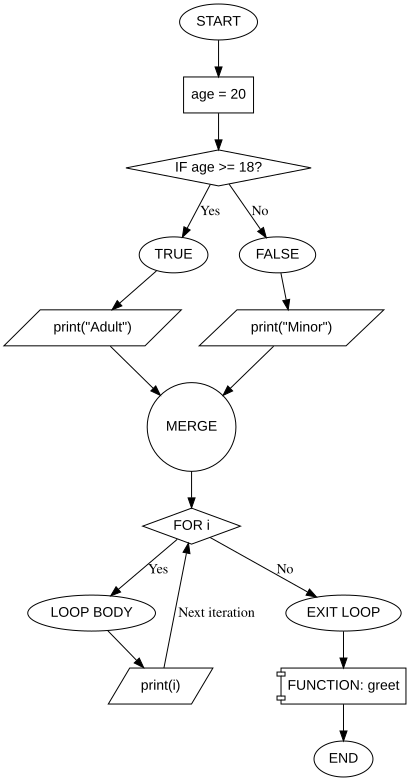

Flowchart generated successfully!


In [6]:

sample_code = """
age = 20

if age >= 18:
    print("Adult")
else:
    print("Minor")

for i in range(3):
    print(i)

def greet():
    return "Hello"
"""

flowchart = generate_flowchart(sample_code)

if flowchart:
    display(flowchart)

    # Save flowchart as PNG
    flowchart.render(
        "/content/code_flowchart",
        format="png",
        cleanup=True
    )

    print("Flowchart generated successfully!")


In [7]:

import os

os.makedirs("core", exist_ok=True)
os.makedirs("web", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


In [8]:

%%writefile core/analyzer.py

import ast

class CodeAnalyzer(ast.NodeVisitor):

    def __init__(self, source_code):
        self.source_code = source_code
        self.results = []

    def add_result(self, node, category, details):
        self.results.append({
            "line": node.lineno,
            "type": category,
            "code": ast.get_source_segment(
                self.source_code, node
            ),
            "details": details
        })

    def visit_Assign(self, node):
        variables = [
            ast.unparse(target)
            for target in node.targets
        ]

        self.add_result(
            node, "Variable Assignment",
            f"Variables: {', '.join(variables)}"
        )
        self.generic_visit(node)

    def visit_AnnAssign(self, node):
        self.add_result(
            node, "Variable Assignment",
            f"Variable: {ast.unparse(node.target)}"
        )
        self.generic_visit(node)

    def visit_Expr(self, node):
        if isinstance(node.value, ast.Call):
            if isinstance(node.value.func, ast.Name):
                if node.value.func.id == "print":
                    self.add_result(
                        node, "Print Statement",
                        "Displays output"
                    )

        self.generic_visit(node)

    def visit_If(self, node):
        self.add_result(
            node, "If Condition",
            f"Condition: {ast.unparse(node.test)}"
        )
        self.generic_visit(node)

    def visit_For(self, node):
        self.add_result(
            node, "For Loop",
            f"Target: {ast.unparse(node.target)}"
        )
        self.generic_visit(node)

    def visit_While(self, node):
        self.add_result(
            node, "While Loop",
            f"Condition: {ast.unparse(node.test)}"
        )
        self.generic_visit(node)

    def visit_FunctionDef(self, node):
        self.add_result(
            node, "Function Definition",
            f"Function: {node.name}"
        )
        self.generic_visit(node)

    def visit_Return(self, node):
        value = ast.unparse(node.value) if node.value else "None"

        self.add_result(
            node, "Return Statement",
            f"Returns: {value}"
        )

    def analyze(self):
        try:
            tree = ast.parse(self.source_code)
            self.visit(tree)

            return sorted(
                self.results,
                key=lambda item: item["line"]
            )

        except SyntaxError as error:
            return {"error": str(error)}

def analyze_code(source_code):
    return CodeAnalyzer(source_code).analyze()

Writing core/analyzer.py


In [9]:

%%writefile core/flowchart.py

import ast
from graphviz import Digraph

class FlowchartGenerator:

    def __init__(self, source_code):
        self.source_code = source_code
        self.graph = Digraph("Code_Flow")
        self.graph.attr(rankdir="TB")
        self.graph.attr("node", fontname="Arial")
        self.counter = 0

    def new_id(self):
        self.counter += 1
        return f"node{self.counter}"

    def add_node(self, label, shape="box"):
        node_id = self.new_id()
        self.graph.node(node_id, label, shape=shape)
        return node_id

    def connect(self, source, target, label=""):
        self.graph.edge(source, target, label=label)

    def build_block(self, statements, incoming):

        for stmt in statements:

            if isinstance(stmt, ast.If):

                decision = self.add_node(
                    f"IF {ast.unparse(stmt.test)}?",
                    "diamond"
                )

                for previous in incoming:
                    self.connect(previous, decision)

                yes = self.add_node("TRUE", "oval")
                no = self.add_node("FALSE", "oval")

                self.connect(decision, yes, "Yes")
                self.connect(decision, no, "No")

                yes_end = self.build_block(
                    stmt.body, [yes]
                )

                no_end = self.build_block(
                    stmt.orelse, [no]
                )

                merge = self.add_node("MERGE", "circle")

                for node in yes_end + no_end:
                    self.connect(node, merge)

                incoming = [merge]

            elif isinstance(stmt, (ast.For, ast.While)):

                if isinstance(stmt, ast.For):
                    label = f"FOR {ast.unparse(stmt.target)}"
                else:
                    label = f"WHILE {ast.unparse(stmt.test)}?"

                loop = self.add_node(label, "diamond")

                for previous in incoming:
                    self.connect(previous, loop)

                body = self.add_node("LOOP BODY", "box")
                self.connect(loop, body, "Yes")

                body_end = self.build_block(
                    stmt.body, [body]
                )

                for node in body_end:
                    self.connect(node, loop, "Repeat")

                exit_node = self.add_node(
                    "EXIT LOOP", "oval"
                )

                self.connect(loop, exit_node, "No")
                incoming = [exit_node]

            else:

                code = (
                    ast.get_source_segment(
                        self.source_code, stmt
                    ) or type(stmt).__name__
                )

                code = code.replace("\n", " ")[:60]

                if isinstance(stmt, ast.FunctionDef):
                    label = f"FUNCTION: {stmt.name}"
                    shape = "component"
                elif isinstance(stmt, ast.Return):
                    label = f"RETURN: {code}"
                    shape = "parallelogram"
                else:
                    label = code
                    shape = "box"

                current = self.add_node(label, shape)

                for previous in incoming:
                    self.connect(previous, current)

                incoming = [current]

        return incoming

    def generate(self):

        tree = ast.parse(self.source_code)

        start = self.add_node("START", "oval")

        end_nodes = self.build_block(
            tree.body, [start]
        )

        end = self.add_node("END", "oval")

        for node in end_nodes:
            self.connect(node, end)

        return self.graph

def generate_flowchart(source_code):

    try:
        generator = FlowchartGenerator(source_code)
        return generator.generate()

    except SyntaxError as error:
        print("Syntax Error:", error)
        return None

Writing core/flowchart.py


In [10]:

%%writefile web/app.py

import streamlit as st
import sys
import os

sys.path.append(
    os.path.abspath(
        os.path.join(os.path.dirname(__file__), "..")
    )
)

from core.analyzer import analyze_code
from core.flowchart import generate_flowchart

st.set_page_config(
    page_title="Visual Code Flow Tracker",
    page_icon="🔍",
    layout="wide"
)

st.title("🔍 Visual Code Flow Tracker")

st.markdown(
    "### Python Code Analysis & Flowchart Visualization"
)

st.write(
    "Enter Python code below to analyze its structure "
    "and generate a visual flowchart."
)

sample_code = '''x = 10
y = 20

if x < y:
    print("X is smaller")
else:
    print("Y is smaller")

for i in range(3):
    print(i)

def greet():
    return "Hello"
'''

source_code = st.text_area(
    "Python Code Editor",
    value=sample_code,
    height=300
)

if st.button("🚀 Analyze & Generate Flowchart"):

    if not source_code.strip():
        st.warning("Please enter some Python code.")

    else:
        results = analyze_code(source_code)

        if isinstance(results, dict) and "error" in results:
            st.error(results["error"])

        else:
            st.subheader("📊 Code Analysis Results")

            if results:
                st.dataframe(
                    results,
                    use_container_width=True
                )
            else:
                st.info("No supported statements detected.")

            st.subheader("🔄 Generated Flowchart")

            flowchart = generate_flowchart(source_code)

            if flowchart:
                st.graphviz_chart(
                    flowchart,
                    use_container_width=True
                )

                png_data = flowchart.pipe(format="png")

                st.download_button(
                    label="⬇️ Download Flowchart PNG",
                    data=png_data,
                    file_name="code_flowchart.png",
                    mime="image/png"
                )

                st.success(
                    "Analysis and Flowchart completed successfully!"
                )

Writing web/app.py


In [11]:

!python -m py_compile core/analyzer.py core/flowchart.py web/app.py

print("All project files passed syntax checking!")


All project files passed syntax checking!


In [12]:
!streamlit run web/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [13]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
added 22 packages in 2s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.2
npm notice To update run: npm install -g npm@12.2.2
npm notice
⠧

In [14]:
!lt --port 8501

your url is: https://lucky-singers-attack.loca.lt
^C


In [15]:
!pip install --upgrade streamlit graphviz

In [16]:
!pkill -f streamlit

In [17]:
!streamlit run web/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true > /content/streamlit.log 2>&1 &

In [18]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.11.0) ...
Setting up cloudflared (2026.11.0) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
!cloudflared tunnel --url http://localhost:8501

2026-11-16T20:21:46Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-16T20:21:46Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-16T20:21:49Z INF +--------------------------------------------------------------------------------------------+
2026-11-16T20:21:49Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-16T20:21:49Z INF |  https://pharmaceuticals-supervisors-clearing-worceste

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [22]:
import requests

try:
    response = requests.get("http://127.0.0.1:8501/_stcore/health")
    print("Server Status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Server Error:", e)

Server Error: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7ef0034ed010>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [23]:
!tail -40 /content/streamlit.log



2026-11-16 19:21:58.521 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.223.234.167:8501

2026-11-16 19:23:32.580 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-16 19:23:32.816 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
  Stopping...


In [24]:
import subprocess
import time
import requests

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "web/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(10)

try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health"
    )

    print("Server Status:", response.status_code)
    print("Response:", response.text)

except Exception as error:
    print("Error:", error)

Server Status: 200
Response: ok


In [27]:
import subprocess

tunnel = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in tunnel.stdout:
    print(line, end="")

    if "trycloudflare.com" in line:
        print("\nYOUR WEBSITE LINK IS READY!")
        break

2026-11-16T19:58:46Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-16T19:58:46Z INF Requesting new quick Tunnel on trycloudflare.com...

YOUR WEBSITE LINK IS READY!


In [31]:
import os

os.makedirs("desktop", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Desktop folders ready!")

Desktop folders ready!


In [32]:
%%writefile desktop/main.py

import tkinter as tk
from tkinter import ttk, messagebox, filedialog
from tkinter.scrolledtext import ScrolledText
from pathlib import Path
import sys

# Import project modules
ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from core.analyzer import analyze_code
from core.flowchart import generate_flowchart


# Application colors
BG = "#111827"
PANEL = "#1F2937"
ACCENT = "#3B82F6"
TEXT = "#F9FAFB"
MUTED = "#9CA3AF"
GREEN = "#10B981"


class VisualCodeTracker:

    def __init__(self, root):

        self.root = root
        self.root.title("Visual Code Flow Tracker")
        self.root.geometry("1200x750")
        self.root.minsize(950, 600)
        self.root.configure(bg=BG)

        self.flowchart = None
        self.flowchart_image = None

        self.setup_style()
        self.create_interface()

    # Configure application style
    def setup_style(self):

        style = ttk.Style()
        style.theme_use("clam")

        style.configure(
            "Treeview",
            background=PANEL,
            foreground=TEXT,
            fieldbackground=PANEL,
            rowheight=30
        )

        style.configure(
            "Treeview.Heading",
            background=ACCENT,
            foreground="white",
            font=("Arial", 10, "bold")
        )

    # Create main interface
    def create_interface(self):

        # Header
        header = tk.Frame(self.root, bg=BG)
        header.pack(fill="x", padx=20, pady=15)

        tk.Label(
            header,
            text="VISUAL CODE FLOW TRACKER",
            font=("Arial", 20, "bold"),
            bg=BG,
            fg=TEXT
        ).pack(side="left")

        tk.Label(
            header,
            text="PYTHON CODE ANALYZER",
            font=("Arial", 10),
            bg=BG,
            fg=GREEN
        ).pack(side="right")

        # Main container
        main = tk.Frame(self.root, bg=BG)
        main.pack(fill="both", expand=True, padx=20, pady=10)

        # Left panel
        left = tk.Frame(main, bg=PANEL)
        left.pack(
            side="left",
            fill="both",
            expand=True,
            padx=(0, 10)
        )

        tk.Label(
            left,
            text="Python Code Editor",
            bg=PANEL,
            fg=TEXT,
            font=("Arial", 14, "bold")
        ).pack(anchor="w", padx=15, pady=10)

        self.editor = ScrolledText(
            left,
            bg="#0B1120",
            fg="#E5E7EB",
            insertbackground="white",
            font=("Consolas", 12),
            wrap="none",
            height=18
        )

        self.editor.pack(
            fill="both",
            expand=True,
            padx=15,
            pady=10
        )

        self.editor.insert(
            "1.0",
            'x = 10\n'
            'y = 20\n\n'
            'if x < y:\n'
            '    print("X is smaller")\n'
            'else:\n'
            '    print("Y is smaller")\n\n'
            'for i in range(3):\n'
            '    print(i)\n'
        )

        # Buttons
        buttons = tk.Frame(left, bg=PANEL)
        buttons.pack(fill="x", padx=15, pady=15)

        self.create_button(
            buttons,
            "Analyze Code",
            self.analyze,
            ACCENT
        )

        self.create_button(
            buttons,
            "Generate Flowchart",
            self.generate,
            GREEN
        )

        self.create_button(
            buttons,
            "Clear",
            self.clear,
            "#DC2626"
        )

        # Right panel
        right = tk.Frame(main, bg=PANEL, width=420)
        right.pack(side="right", fill="both")
        right.pack_propagate(False)

        tk.Label(
            right,
            text="Analysis Results",
            bg=PANEL,
            fg=TEXT,
            font=("Arial", 14, "bold")
        ).pack(anchor="w", padx=15, pady=10)

        self.results = ttk.Treeview(
            right,
            columns=("line", "type"),
            show="headings"
        )

        self.results.heading("line", text="Line")
        self.results.heading("type", text="Code Element")

        self.results.column("line", width=60)
        self.results.column("type", width=300)

        self.results.pack(
            fill="both",
            expand=True,
            padx=15,
            pady=10
        )

        # Status bar
        self.status = tk.Label(
            self.root,
            text="Ready | Visual Code Flow Tracker",
            bg="#0B1120",
            fg=GREEN,
            anchor="w",
            padx=15
        )

        self.status.pack(fill="x", side="bottom")

    # Create styled buttons
    def create_button(self, parent, text, command, color):

        tk.Button(
            parent,
            text=text,
            command=command,
            bg=color,
            fg="white",
            activebackground=color,
            activeforeground="white",
            font=("Arial", 10, "bold"),
            relief="flat",
            padx=12,
            pady=9,
            cursor="hand2"
        ).pack(side="left", padx=5)

    # Get source code
    def get_code(self):
        return self.editor.get("1.0", "end-1c")

    # Analyze Python code
    def analyze(self):

        code = self.get_code()

        if not code.strip():
            messagebox.showwarning(
                "Warning",
                "Please enter Python code."
            )
            return

        results = analyze_code(code)

        if isinstance(results, dict):
            messagebox.showerror(
                "Syntax Error",
                results["error"]
            )
            return

        for item in self.results.get_children():
            self.results.delete(item)

        for item in results:

            self.results.insert(
                "",
                "end",
                values=(
                    item["line"],
                    item["type"]
                )
            )

        self.status.config(
            text=f"Analysis completed | {len(results)} elements detected"
        )

    # Generate flowchart
    def generate(self):

        code = self.get_code()

        if not code.strip():
            messagebox.showwarning(
                "Warning",
                "Please enter Python code."
            )
            return

        graph = generate_flowchart(code)

        if graph is None:
            messagebox.showerror(
                "Error",
                "Unable to generate flowchart."
            )
            return

        try:

            output_dir = ROOT / "outputs"
            output_dir.mkdir(exist_ok=True)

            output_path = output_dir / "code_flowchart"

            graph.render(
                str(output_path),
                format="png",
                cleanup=True
            )

            image_path = str(output_path) + ".png"

            self.show_flowchart(image_path)

            self.flowchart = image_path

            self.status.config(
                text="Flowchart generated successfully!"
            )

        except Exception as error:

            messagebox.showerror(
                "Flowchart Error",
                str(error)
            )

    # Display flowchart
    def show_flowchart(self, image_path):

        preview = tk.Toplevel(self.root)
        preview.title("Generated Flowchart")
        preview.configure(bg=BG)

        image = tk.PhotoImage(file=image_path)

        max_width = 1000
        max_height = 700

        scale = max(
            1,
            (image.width() + max_width - 1) // max_width,
            (image.height() + max_height - 1) // max_height
        )

        if scale > 1:
            image = image.subsample(scale, scale)

        self.flowchart_image = image

        tk.Label(
            preview,
            text="Generated Code Flowchart",
            bg=BG,
            fg=TEXT,
            font=("Arial", 16, "bold")
        ).pack(pady=10)

        tk.Label(
            preview,
            image=self.flowchart_image,
            bg=BG
        ).pack(padx=10, pady=10)

        tk.Button(
            preview,
            text="Download Flowchart",
            command=self.download,
            bg=ACCENT,
            fg="white",
            padx=15,
            pady=8
        ).pack(pady=10)

    # Download PNG
    def download(self):

        if not self.flowchart:
            return

        destination = filedialog.asksaveasfilename(
            defaultextension=".png",
            filetypes=[("PNG Image", "*.png")]
        )

        if destination:

            import shutil
            shutil.copy2(self.flowchart, destination)

            messagebox.showinfo(
                "Success",
                "Flowchart saved successfully!"
            )

    # Clear editor
    def clear(self):

        self.editor.delete("1.0", "end")

        for item in self.results.get_children():
            self.results.delete(item)

        self.status.config(text="Editor cleared")


# Run application
if __name__ == "__main__":

    root = tk.Tk()

    app = VisualCodeTracker(root)

    root.mainloop()

Writing desktop/main.py


In [33]:
!python -m py_compile desktop/main.py

print("Desktop application code is ready!")

Desktop application code is ready!
